# Análisis exploratorio — flotilla Canadá 2023

Este notebook cuenta la historia del archivo `data/raw/canada_2023_flotilla.csv`: qué contiene, qué tan completo está, qué se puede (y qué **no** se puede) concluir, y cómo se ve el reporte con un año completo usando datos **sintéticos claramente etiquetados**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from fleet_analytics import charts, synthetic
from fleet_analytics.cleaning import coverage_matrix, load_raw, split_totals, to_long
from fleet_analytics.metrics import (co2e_by_fuel, fuel_share, headline, monthly_trend,
                                     segment_summary, with_unit_metrics)
from fleet_analytics.validation import validate

%matplotlib inline
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.max_colwidth', 110)
CSV = ROOT / 'data' / 'raw' / 'canada_2023_flotilla.csv'

## 1. Inspección del archivo crudo

Se lee todo como texto para no perder información (comas de miles, signos `$`).

In [2]:
raw = load_raw(CSV)
monthly, totals = split_totals(raw)
print('Encoding: UTF-8 / ASCII puro (sin acentos ni BOM)')
print('Filas totales:', len(raw), '| mensuales:', len(monthly), '| filas Total:', len(totals))
print('Columnas:', raw.shape[1])
value_cols = [c for c in raw.columns if c not in ['Month','Year','Country','Ownership','Type']]
empty = (monthly[value_cols] == '').to_numpy().mean()
print(f'Celdas numéricas vacías en filas mensuales: {empty:.1%}')
raw.head(7)

Encoding: UTF-8 / ASCII puro (sin acentos ni BOM)
Filas totales: 91 | mensuales: 84 | filas Total: 7
Columnas: 30
Celdas numéricas vacías en filas mensuales: 96.2%


,Month,Year,Country,Ownership,Type,Quantity,Gasoline_km,Gasoline_lt,Gasoline_$ (US Dlls),Gasoline_Quantity,...,LPG(gas)_$ (US Dlls),LPG(gas)_Quantity,NCG (gas)_km,NCG (gas)_lt,NCG (gas)_$ (US Dlls),NCG (gas)_Quantity,Electric_km,Electric_kWh,Electric_$ (US Dlls),Electric_Quantity
0,January,2023,Canada,"owned, leased or renting",tractor,,,,,,...,,,,,,,,,,
1,January,2023,Canada,"owned, leased or renting",route trucks,,,,,,...,,,,,,,,,,
2,January,2023,Canada,"owned, leased or renting",supervision,,,,,,...,,,,,,,,,,
3,January,2023,Canada,"owned, leased or renting",executives,,,,,,...,,,,,,,,,,
4,January,2023,Canada,"owned, leased or renting",others,,,,,,...,,,,,,,,,,
5,January,2023,Canada,Independent Operators,route trucks,"1,100",,,,,...,,,,,,,,,,
6,January,2023,Canada,Logistic Operators (3PL),tractor,,,,,,...,,,,,,,,,,


### Cobertura: ¿qué segmento tiene datos en qué mes?

In [3]:
cov = coverage_matrix(raw).astype(int)
cov.columns = charts.MONTH_ABBR
cov

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
segment,,,,,,,,,,,,
Independent Operators | route trucks,1,1,1,1,1,1,1,1,1,1,1,1
Logistic Operators (3PL) | tractor,1,1,1,1,1,0,0,0,0,0,0,0
"owned, leased or renting | executives",0,0,0,0,0,0,0,0,0,0,0,0
"owned, leased or renting | others",0,0,0,0,0,0,0,0,0,0,0,0
"owned, leased or renting | route trucks",0,0,0,0,0,0,0,0,0,0,0,0
"owned, leased or renting | supervision",0,0,0,0,0,0,0,0,0,0,0,0
"owned, leased or renting | tractor",0,0,0,0,0,0,0,0,0,0,0,0


**Lectura:** sólo 2 de 7 segmentos tienen datos. Los 5 segmentos de flota propia/arrendada (`owned, leased or renting`) están vacíos todo el año. *Logistic Operators (3PL) · tractor* sólo reporta enero–mayo. Y de los 6 combustibles del template sólo hay **diésel**.

## 2. Formato largo (tidy)

Una fila por mes × segmento × combustible, sólo con combinaciones que tienen datos.

In [4]:
long = to_long(raw)
print(long.shape)
long.head()

(17, 14)


,source,year,month,month_name,country,ownership,vehicle_type,fleet_quantity,fuel,unit,km,volume,cost_usd,vehicles
0,real,2023,1,January,Canada,Independent Operators,route trucks,"1,100.000",diesel,L,"2,028,000.000","507,000.000","668,987.000","1,100.000"
1,real,2023,1,January,Canada,Logistic Operators (3PL),tractor,NaN,diesel,L,"2,617,467.000","1,177,860.150","1,721,771.430",849.000
2,real,2023,2,February,Canada,Independent Operators,route trucks,"1,100.000",diesel,L,"2,028,000.000","507,000.000","668,987.000","1,100.000"
3,real,2023,2,February,Canada,Logistic Operators (3PL),tractor,NaN,diesel,L,"2,443,422.000","1,099,539.900","1,447,795.660",849.000
4,real,2023,3,March,Canada,Independent Operators,route trucks,"1,100.000",diesel,L,"2,028,000.000","507,000.000","668,987.000","1,100.000"


## 3. Validación

In [5]:
issues = validate(raw, long)
print(issues['severity'].value_counts().to_string())
issues

severity
info    14


,severity,rule,segment,month,message
0,info,R6_constant_ratio,Independent Operators | route trucks | diesel,todos,"Rendimiento idéntico en 12 meses (4.0000 km/L): probablemente derivado con un factor fijo, no medido"
1,info,R6_constant_ratio,Independent Operators | route trucks | diesel,todos,"Costo unitario idéntico en 12 meses (1.3195 USD/L): probablemente derivado con un factor fijo, no medido"
2,info,R6_constant_ratio,Logistic Operators (3PL) | tractor | diesel,todos,"Rendimiento idéntico en 5 meses (2.2222 km/L): probablemente derivado con un factor fijo, no medido"
3,info,R7_fleet_quantity,Logistic Operators (3PL) | tractor | diesel,January,Quantity general vacío; el combustible reporta 849 vehículos
4,info,R7_fleet_quantity,Logistic Operators (3PL) | tractor | diesel,February,Quantity general vacío; el combustible reporta 849 vehículos
5,info,R7_fleet_quantity,Logistic Operators (3PL) | tractor | diesel,March,Quantity general vacío; el combustible reporta 868 vehículos
6,info,R7_fleet_quantity,Logistic Operators (3PL) | tractor | diesel,April,Quantity general vacío; el combustible reporta 868 vehículos
7,info,R7_fleet_quantity,Logistic Operators (3PL) | tractor | diesel,May,Quantity general vacío; el combustible reporta 864 vehículos
8,info,R9_coverage,"owned, leased or renting | tractor",todos,Segmento sin ningún dato en el año
9,info,R9_coverage,"owned, leased or renting | route trucks",todos,Segmento sin ningún dato en el año


**Hallazgos de calidad:**

- No hay errores ni advertencias: los valores son positivos, completos, dentro de rangos plausibles, y la suma de los meses concilia con las filas `Total` del archivo.
- **Rendimiento constante**: *route trucks* da exactamente 4.0000 km/L los 12 meses y el 3PL 2.2222 km/L (= 1/0.45 L/km) los 5 meses. Eso casi nunca ocurre con mediciones reales: sugiere que los litros (o los km) se **calcularon con un factor fijo**. Por lo tanto el rendimiento de este archivo *no* es un hallazgo operativo, es un supuesto de quien llenó el template.
- El precio por litro de *route trucks* también es constante (1.3195 USD/L).
- En el 3PL la columna general `Quantity` está vacía aunque `Diesel_Quantity` sí reporta vehículos.

## 4. Métricas por segmento

In [6]:
summary = segment_summary(long)
summary[['ownership','vehicle_type','fuel','months_reported','vehicles','km','volume','cost_usd',
         'efficiency','l_per_100km','cost_per_km','cost_per_unit','km_per_vehicle','co2e_g_per_km']]

,ownership,vehicle_type,fuel,months_reported,vehicles,km,volume,cost_usd,efficiency,l_per_100km,cost_per_km,cost_per_unit,km_per_vehicle,co2e_g_per_km
0,Independent Operators,route trucks,diesel,12,"1,100.000","26,364,000.000","6,591,000.000","8,696,828.000",4.000,25.000,0.330,1.320,"23,967.273",670.000
1,Logistic Operators (3PL),tractor,diesel,5,868.000,"13,957,605.000","6,280,922.250","7,952,535.700",2.222,45.000,0.570,1.266,"16,080.190","1,206.000"


In [7]:
headline(long)

{'km': 40321605.0,
 'liters': 12871922.25,
 'kwh': 0.0,
 'cost_usd': 16649363.7,
 'co2e_t': 34496.75163,
 'cost_per_km': 0.41291421063224043,
 'segments': 2,
 'months': 12}

## 5. Tendencias mensuales

In [8]:
m = with_unit_metrics(long)
m['km_ratio_vs_min'] = m['km'] / m.groupby('vehicle_type')['km'].transform('min')
m[['month_name','vehicle_type','vehicles','km','km_ratio_vs_min','cost_per_unit','km_per_vehicle','cost_per_km']]

,month_name,vehicle_type,vehicles,km,km_ratio_vs_min,cost_per_unit,km_per_vehicle,cost_per_km
0,January,route trucks,"1,100.000","2,028,000.000",1.000,1.320,"1,843.636",0.330
1,January,tractor,849.000,"2,617,467.000",1.071,1.462,"3,083.000",0.658
2,February,route trucks,"1,100.000","2,028,000.000",1.000,1.320,"1,843.636",0.330
3,February,tractor,849.000,"2,443,422.000",1.000,1.317,"2,878.000",0.593
4,March,route trucks,"1,100.000","2,028,000.000",1.000,1.320,"1,843.636",0.330
5,March,tractor,868.000,"2,851,380.000",1.167,1.238,"3,285.000",0.557
6,April,route trucks,"1,100.000","2,028,000.000",1.000,1.320,"1,843.636",0.330
7,April,tractor,868.000,"2,796,696.000",1.145,1.212,"3,222.000",0.546
8,May,route trucks,"1,100.000","2,535,000.000",1.250,1.319,"2,304.545",0.330
9,May,tractor,864.000,"3,248,640.000",1.330,1.141,"3,760.000",0.514


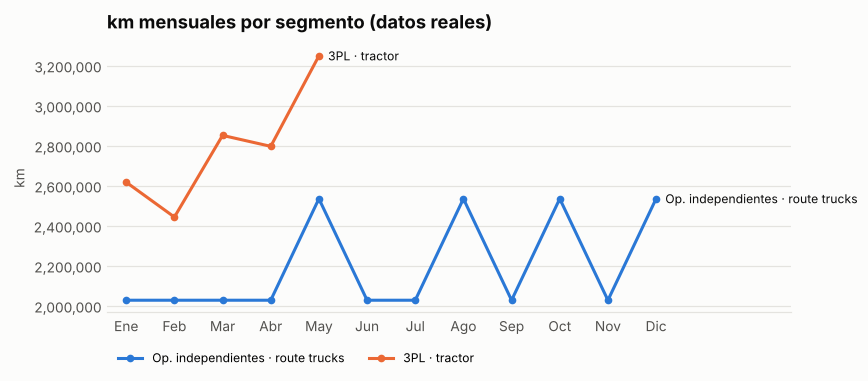

In [9]:
trend = monthly_trend(long, by=['ownership', 'vehicle_type'])
fig = charts.monthly_by_segment(trend, 'km', 'km mensuales por segmento (datos reales)', 'km')

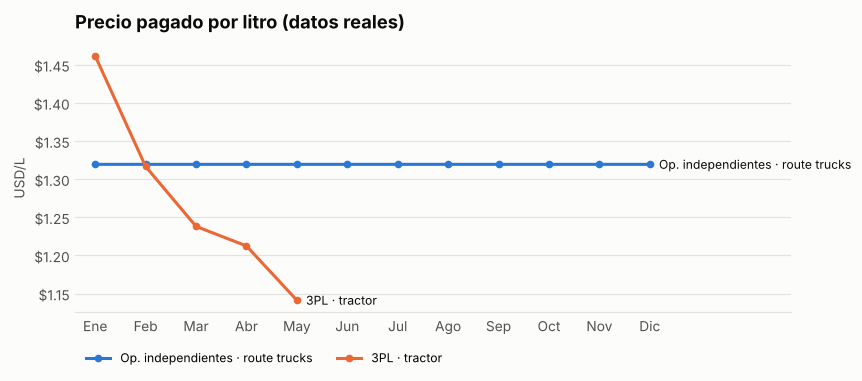

In [10]:
fig = charts.monthly_by_segment(trend, 'cost_per_unit', 'Precio pagado por litro (datos reales)', 'USD/L', '${x:,.2f}')

**Lectura de tendencias (datos reales):**

- *Route trucks* (operadores independientes) sólo toma dos valores: 2,028,000 km o 2,535,000 km, exactamente ×1.25. Es consistente con un cálculo de 507,000 km por semana × 4 o × 5 semanas (meses de 5 semanas: mayo, agosto, octubre y diciembre): de nuevo, **cifras estimadas**, no lecturas de odómetro.
- *3PL tractor*: los km sí varían (2.44 M a 3.25 M) y el precio pagado por litro baja de 1.46 a 1.14 USD/L entre enero y mayo (−22 %). Con sólo 5 meses y litros derivados de los km, conviene confirmarlo con facturas.
- Costo por km: el 3PL cuesta ~0.57 USD/km vs ~0.33 USD/km de route trucks, principalmente porque el factor de rendimiento supuesto es mucho menor (2.22 vs 4.0 km/L), coherente con tractocamiones vs camiones de reparto.

## 6. Emisiones estimadas

In [11]:
co2e_by_fuel(long)

,source,fuel,unit,volume,co2e_kg,co2e_t,factor_kg_per_unit
0,real,diesel,L,"12,871,922.250","34,496,751.630","34,496.752",2.680


Con el factor aproximado de 2.68 kg CO2e/L de diésel, el año reportado suma ~34,500 t CO2e (~17,700 t route trucks, ~16,800 t 3PL en sólo 5 meses). Es un **piso**: faltan 7 meses del 3PL y toda la flota propia.

## 7. Año completo con datos SINTÉTICOS

> **Aviso:** todo lo que sigue usa `fleet_analytics.synthetic.generate()`. Son números inventados con el mismo formato del template para mostrar el comportamiento del reporte con 7 segmentos y 5 combustibles. Cada fila lleva `source = 'synthetic'`.

In [12]:
synth_raw = synthetic.generate(seed=42)
synth = to_long(synth_raw, source='synthetic')
print(synth['source'].unique(), synth.shape)
fuel_share(synth, 'cost_usd')

<StringArray>
['synthetic']
Length: 1, dtype: str (120, 14)


,source,fuel,cost_usd,share
0,synthetic,diesel,"39,296,847.960",0.973
1,synthetic,gasoline,"566,609.800",0.014
2,synthetic,cng,"389,862.780",0.010
3,synthetic,electric,"72,480.760",0.002
4,synthetic,lpg,"59,682.480",0.001


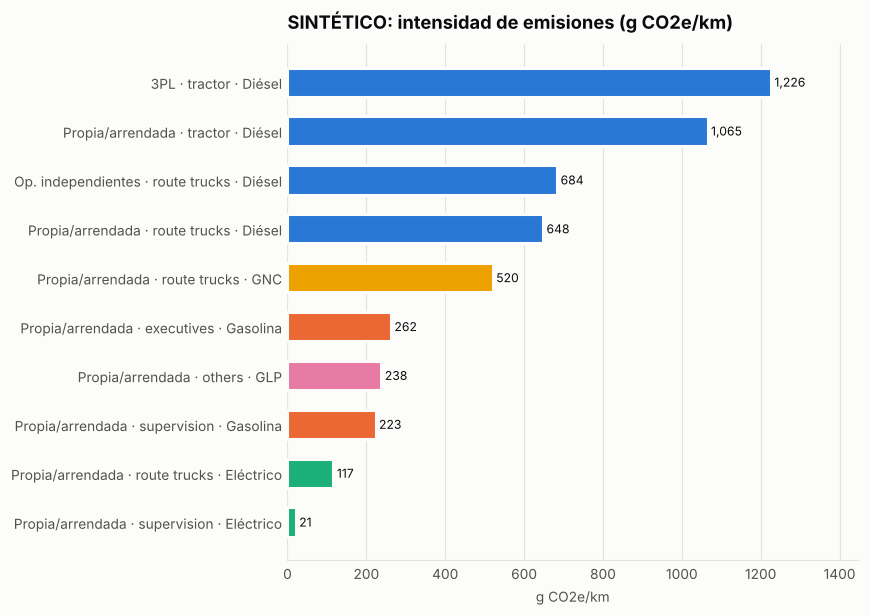

In [13]:
fig = charts.segment_bars(segment_summary(synth), 'co2e_g_per_km',
                          'SINTÉTICO: intensidad de emisiones (g CO2e/km)', 'g CO2e/km', '{:,.0f}')

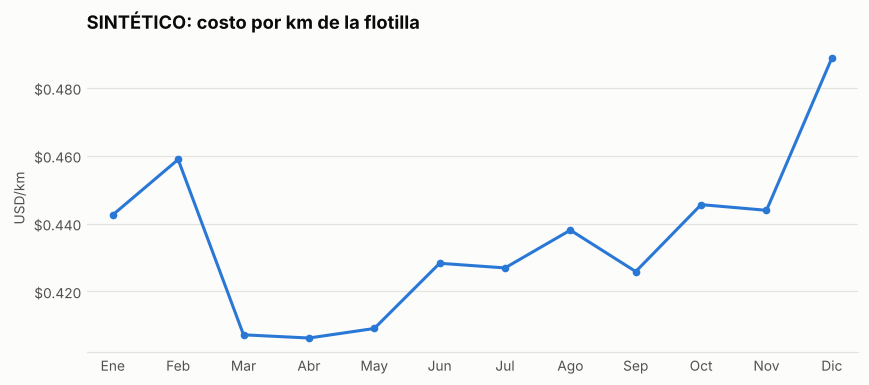

In [14]:
fig = charts.monthly_total(monthly_trend(synth, by=[]), 'cost_per_km',
                           'SINTÉTICO: costo por km de la flotilla', 'USD/km', '${x:,.3f}')

## 8. Conclusiones

1. El archivo real es un **template mayormente vacío**: 17 combinaciones mes-segmento con datos de 84, un solo combustible.
2. Las cifras presentes parecen **estimaciones con factores fijos** (rendimiento y precio constantes, km en múltiplos semanales). Sirven para dimensionar orden de magnitud (≈40 M km, ≈12.9 M L, ≈16.6 M USD, ≈34.5 kt CO2e) pero no para comparar eficiencia real.
3. El valor del proyecto es el **pipeline**: limpieza robusta del template, validación explícita, métricas con definiciones claras y un reporte HTML reproducible que funcionará igual cuando el template se llene.

Para generar los reportes: `python -m fleet_analytics report data/raw/canada_2023_flotilla.csv` y `python -m fleet_analytics report --synthetic`.